# Learned receivers: verify the simulator before trusting BER
        Work from symbol energy and bit mapping to exact inverse checks and measured
        receiver comparisons. [Chapter](../docs/06_signal_equalization.md).

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
while not (root / 'pyproject.toml').exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / 'src'))
def evidence(study):
    return json.loads((root / 'results' / 'reference' / study / 'metrics.json').read_text())
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False, 'axes.spines.right': False})

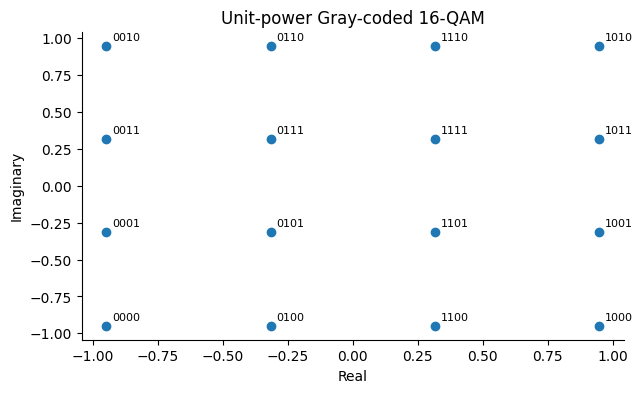

In [2]:
from learning_lab.signals import constellation, channel, physics_inverse, error_metrics
points, bits = constellation()
assert np.isclose(np.mean(abs(points)**2),1)
grid = bits.reshape(4,4,4)
assert np.all(np.sum(grid[1:] != grid[:-1],axis=-1)==1)
plt.scatter(points.real,points.imag)
for p,b in zip(points,bits):
    plt.annotate(''.join(map(str,b)),(p.real,p.imag),xytext=(4,4),textcoords='offset points',fontsize=8)
plt.xlabel('Real'); plt.ylabel('Imaginary'); plt.title('Unit-power Gray-coded 16-QAM'); plt.show()

## Exact reconstruction in the noiseless limit
        Circular FIR memory gives a well-defined Fourier inverse. Newton iteration
        removes the declared amplitude nonlinearity before the linear inverse.

In [3]:
rng = np.random.default_rng(12)
labels = rng.integers(16,size=(100,64))
transmitted = points[labels]
received = channel(transmitted,np.inf,.2,rng)
recovered = physics_inverse(received,.2)
np.testing.assert_allclose(recovered,transmitted,atol=1e-10)
prediction = np.argmin(abs(recovered[:,:,None]-points),axis=-1)
print(error_metrics(labels,prediction))

{'ber': 0.0, 'ser': 0.0, 'ber_ci95': [0.0, 0.0], 'blocks': 100, 'bits': 25600}


## Channel knowledge is a resource
        The inverse knows test parameters, while learned receivers are fitted at one
        channel setting. Test data is generated as independent blocks.

In [4]:
rows = pd.DataFrame(evidence('signals')['rows'])
rows[rows.snr_db==18].groupby(['gamma','model'])[['ber','ser']].agg(['mean','std'])

ber                 ser          
                                 mean       std      mean       std
gamma model                                                        
0.2   cnn                    0.000510  0.000021  0.002036  0.000080
      known_channel_inverse  0.000163  0.000005  0.000654  0.000020
      mlp                    0.000871  0.000031  0.003482  0.000123
      nearest_raw            0.129209  0.000199  0.465760  0.001048
      ridge_window           0.004351  0.000151  0.017305  0.000619
0.4   cnn                    0.001663  0.000165  0.006565  0.000648
      known_channel_inverse  0.000069  0.000007  0.000276  0.000030
      mlp                    0.002273  0.000245  0.009010  0.000958
      nearest_raw            0.133639  0.000338  0.480620  0.001365
      ridge_window           0.011273  0.000189  0.043029  0.000584

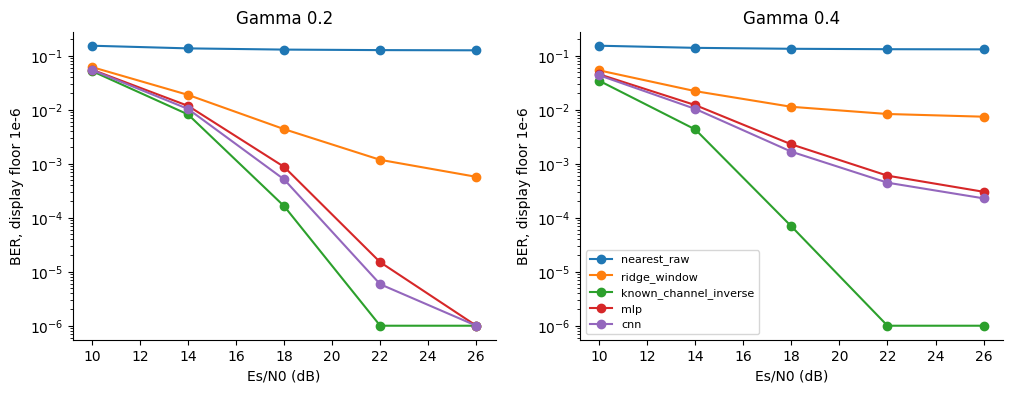

In [5]:
fig,axes = plt.subplots(1,2,figsize=(12,4))
for ax,gamma in zip(axes,[.2,.4]):
    for model,frame in rows[rows.gamma==gamma].groupby('model',sort=False):
        curve = frame.groupby('snr_db').ber.mean()
        ax.semilogy(curve.index,np.maximum(curve,1e-6),'o-',label=model)
    ax.set_title(f'Gamma {gamma}'); ax.set_xlabel('Es/N0 (dB)'); ax.set_ylabel('BER, display floor 1e-6')
axes[1].legend(fontsize=8); plt.show()

## Exercise and worked answer
        Why bootstrap blocks instead of individual bits? Context receivers and channel
        memory correlate errors within a block. Resampling whole independent blocks
        preserves that structure. A measured zero BER is an observation over a finite
        number of bits, not a proof of a perfect receiver. This discrete simulator does
        not establish performance on a physical optical link.